# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model, metrics, model_selection
from sklearn.linear_model import ElasticNet

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [34]:
df = pd.read_csv("./data/Advertising.csv")

df.head()

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0


In [35]:
df = df.drop(columns= ["Unnamed: 0"])
df.head()

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        200 non-null    float64
 1   radio     200 non-null    float64
 2   newpaper  200 non-null    str    
 3   sales     200 non-null    float64
dtypes: float64(3), str(1)
memory usage: 6.4 KB


In [37]:
df[pd.to_numeric(df['newpaper'], errors='coerce').isna()]

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0


In [38]:
df['newpaper'] = df['newpaper'].astype(str).str.replace('s', '')

df['newpaper'] = pd.to_numeric(df['newpaper'])

df.head()

,TV,radio,newpaper,sales
0,230.1,37.8,69.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


In [39]:
df.describe()

,TV,radio,newpaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


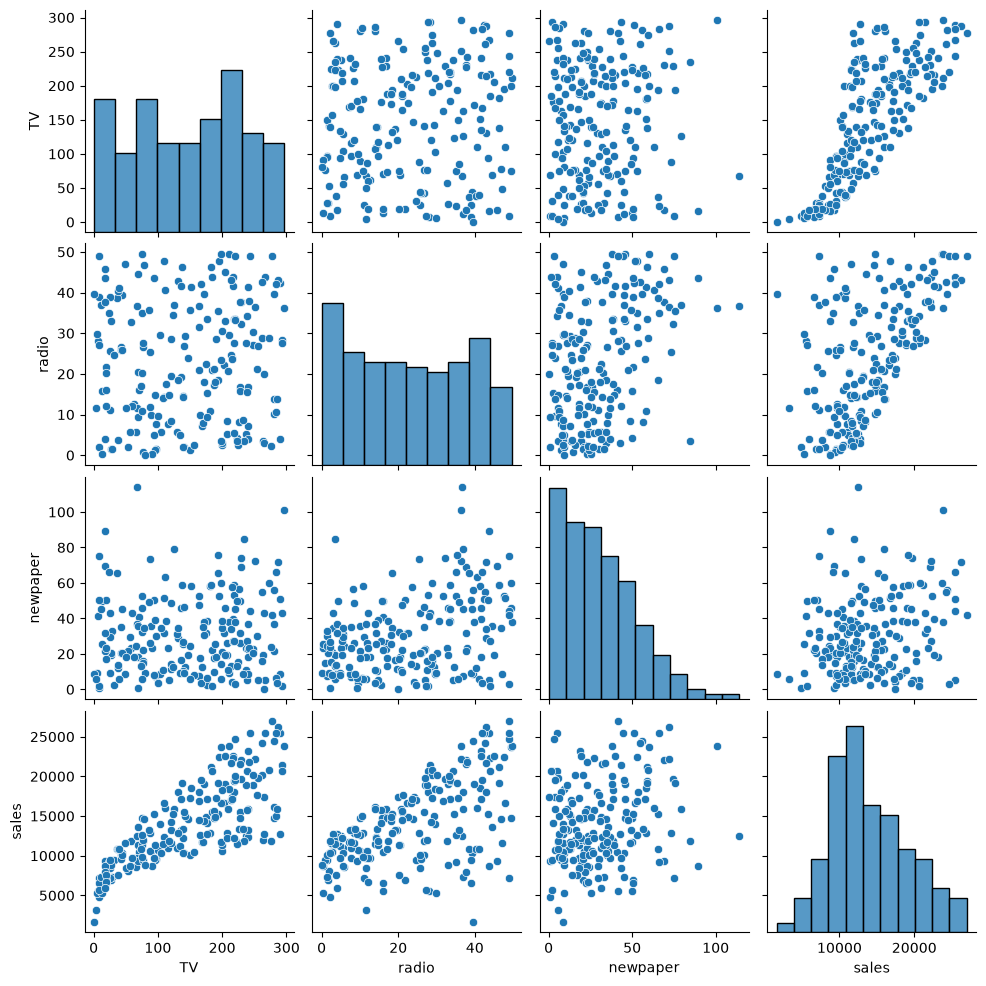

In [40]:
sns.pairplot(df);

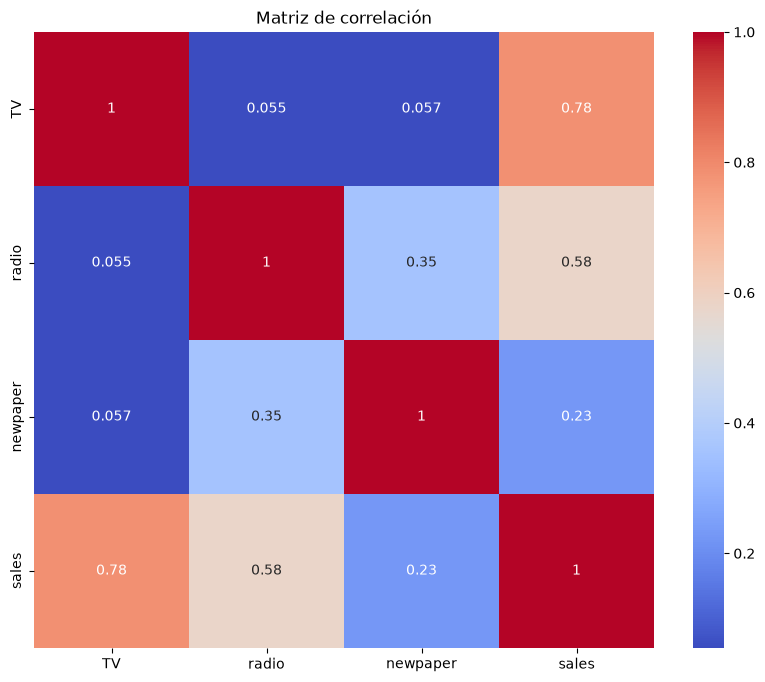

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

In [42]:
# Lectura datos, relación variables, mapas de correlación...

In [43]:
# Utiliza todas las celdas que necesites...

## Modelado

In [44]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

In [45]:
X = df.drop(columns=["sales"])
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [46]:
from sklearn import preprocessing

std_scale = preprocessing.StandardScaler().fit(X_train)
X_train_scal = std_scale.transform(X_train)

lm_scal = LinearRegression()
lm_scal.fit(X_train_scal, y_train)

intercept_scal = lm_scal.intercept_
features_std = pd.DataFrame(lm_scal.coef_, X_train.columns, columns=['coefficient'])

features_std.sort_values('coefficient', ascending=False)

,coefficient
TV,3764.196175
radio,2792.306650
newpaper,55.975514


In [47]:
X_test_scal = std_scale.transform(X_test)

y_test_pred = lm_scal.predict(X_test_scal)

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("MAPE:", mean_absolute_percentage_error(y_test, y_test_pred))
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
print("r2_score test",lm_scal.score(X_test_scal, y_test))

MAE: 1460.7567168117607
MAPE: 0.15198846602831234
MSE: 3174097.353976108
RMSE: 1781.5996615334514
r2_score test 0.8994380241009119


In [48]:
pred_train = lm_scal.predict(X_train_scal)

print("MAE train:", mean_absolute_error(y_train, pred_train))
print("MAPE train:", mean_absolute_percentage_error(y_train, pred_train))
print("MSE train:", mean_squared_error(y_train, pred_train))
print("RMSE train:", np.sqrt(mean_squared_error(y_train, pred_train)))
print("r2_score train", lm_scal.score(X_train_scal, y_train))

MAE train: 1198.4678961500133
MAPE train: 0.13651462127119013
MSE train: 2705129.423081415
RMSE train: 1644.7277656443375
r2_score train 0.8957008271017817


In [49]:
baseline_error = metrics.mean_squared_error(y_test, y_test_pred)

In [50]:
df.describe()

,TV,radio,newpaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


In [51]:
from sklearn.linear_model import Ridge

ridgeR = Ridge(alpha = 0.001)
ridgeR.fit(X_train_scal, y_train)

print("Train MSE sin regularización:", round(metrics.mean_squared_error(y_train, lm_scal.predict(X_train_scal)),2))
print("Test MSE sin regularización:", round(metrics.mean_squared_error(y_test, lm_scal.predict(X_test_scal)),2))

print("Train MSE con regularización:", round(metrics.mean_squared_error(y_train, ridgeR.predict(X_train_scal)),2))
print("Test MSE con regularización:", round(metrics.mean_squared_error(y_test, ridgeR.predict(X_test_scal)),2))
# print("Test RMSE:", np.sqrt(metrics.mean_squared_error(y_test, ridgeR.predict(X_test))))

Train MSE sin regularización: 2705129.42
Test MSE sin regularización: 3174097.35
Train MSE con regularización: 2705129.42
Test MSE con regularización: 3174116.62


In [52]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scal, y_train)
    
    coef_ridge.append(ridge.coef_)
    
    y_pred = ridge.predict(X_test_scal)
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge.append(ridge_error)
    baseline.append(baseline_error)

In [53]:
min(err_ridge)

3174099.2809461346

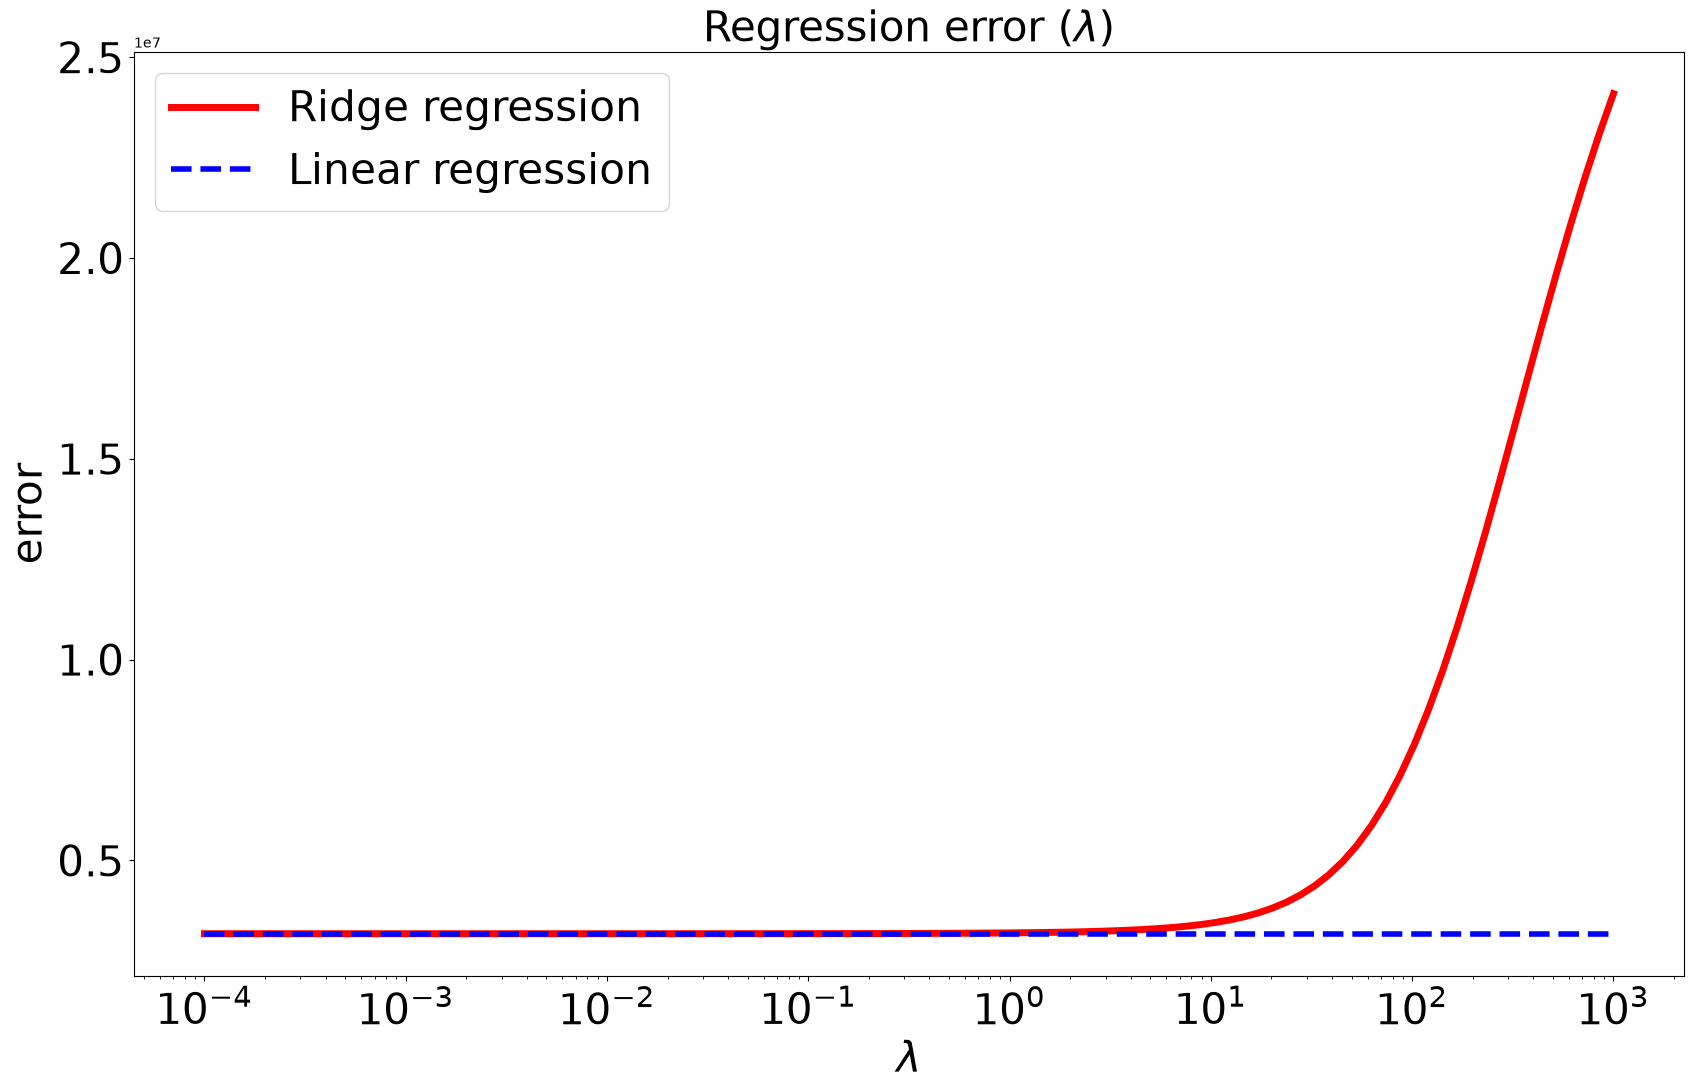

In [54]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [55]:
lasso = linear_model.Lasso()

coef_lasso = []
err_lasso = []

for a in alphas:
    lasso.set_params(alpha=a)
    lasso.fit(X_train_scal, y_train)
    coef_lasso.append(lasso.coef_)
    y_pred = lasso.predict(X_test_scal)
    lasso_error = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso.append(lasso_error)

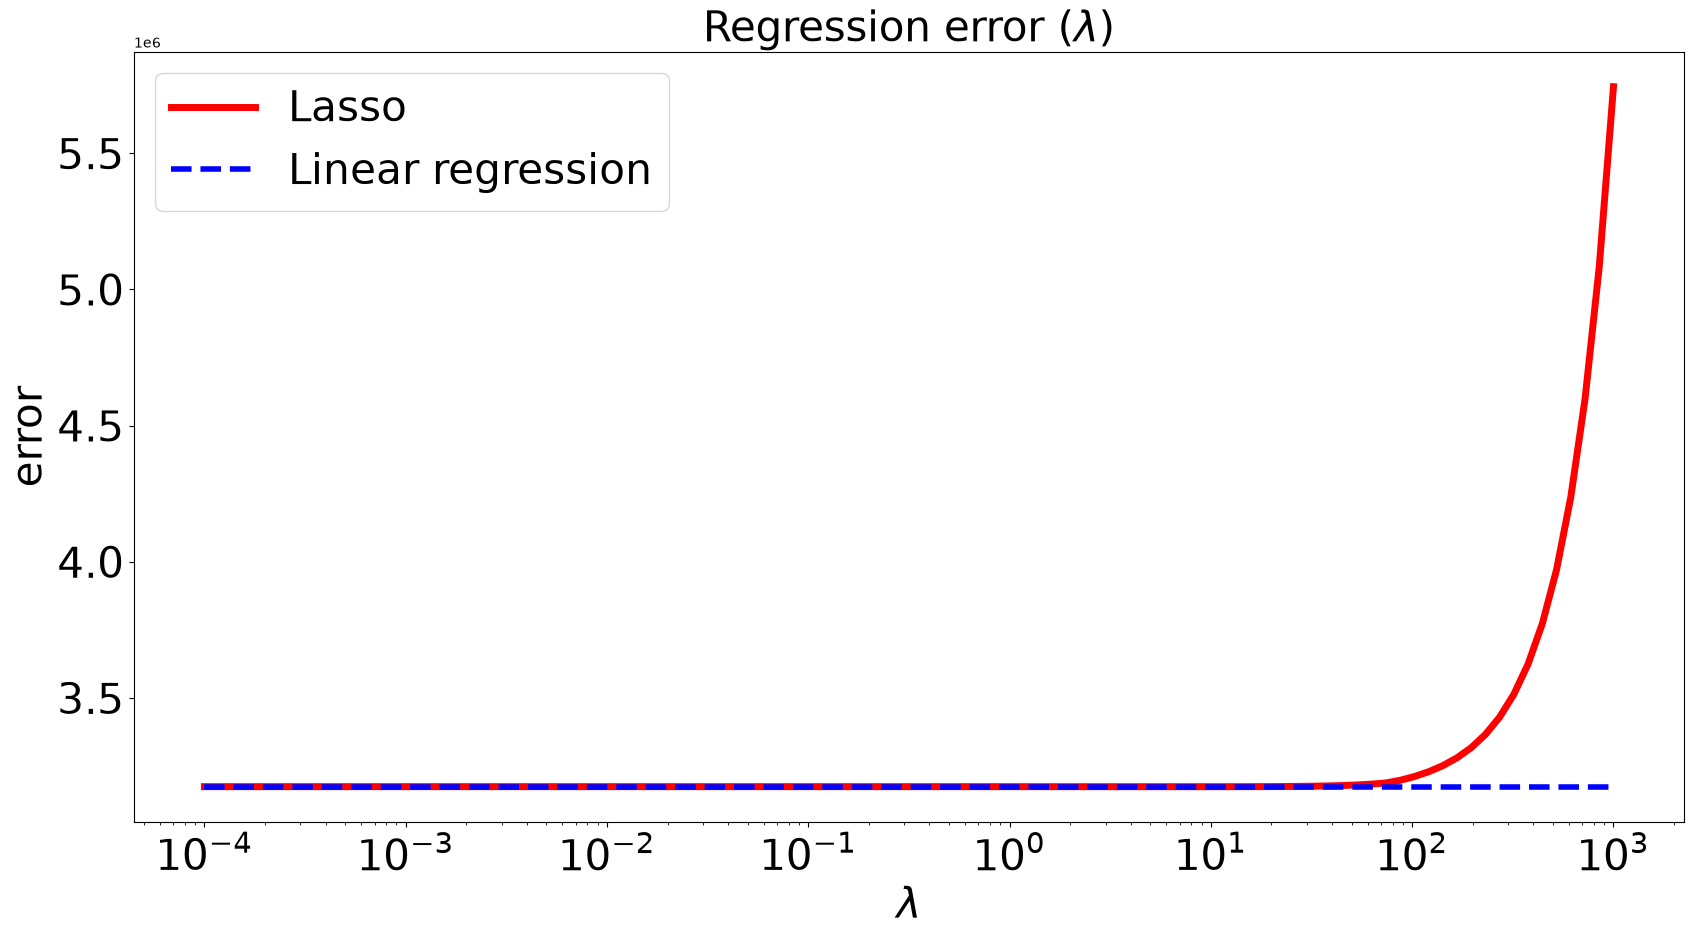

In [56]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [57]:
coef_eln = []
err_eln = []
baseline = []
for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_train_scal, y_train)
    coef_eln.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test_scal)
    elasticnet_error = metrics.mean_squared_error(y_pred, y_test)
    err_eln.append(elasticnet_error)
    baseline.append(baseline_error)
    

In [58]:
min(err_eln)

3174251.561251843

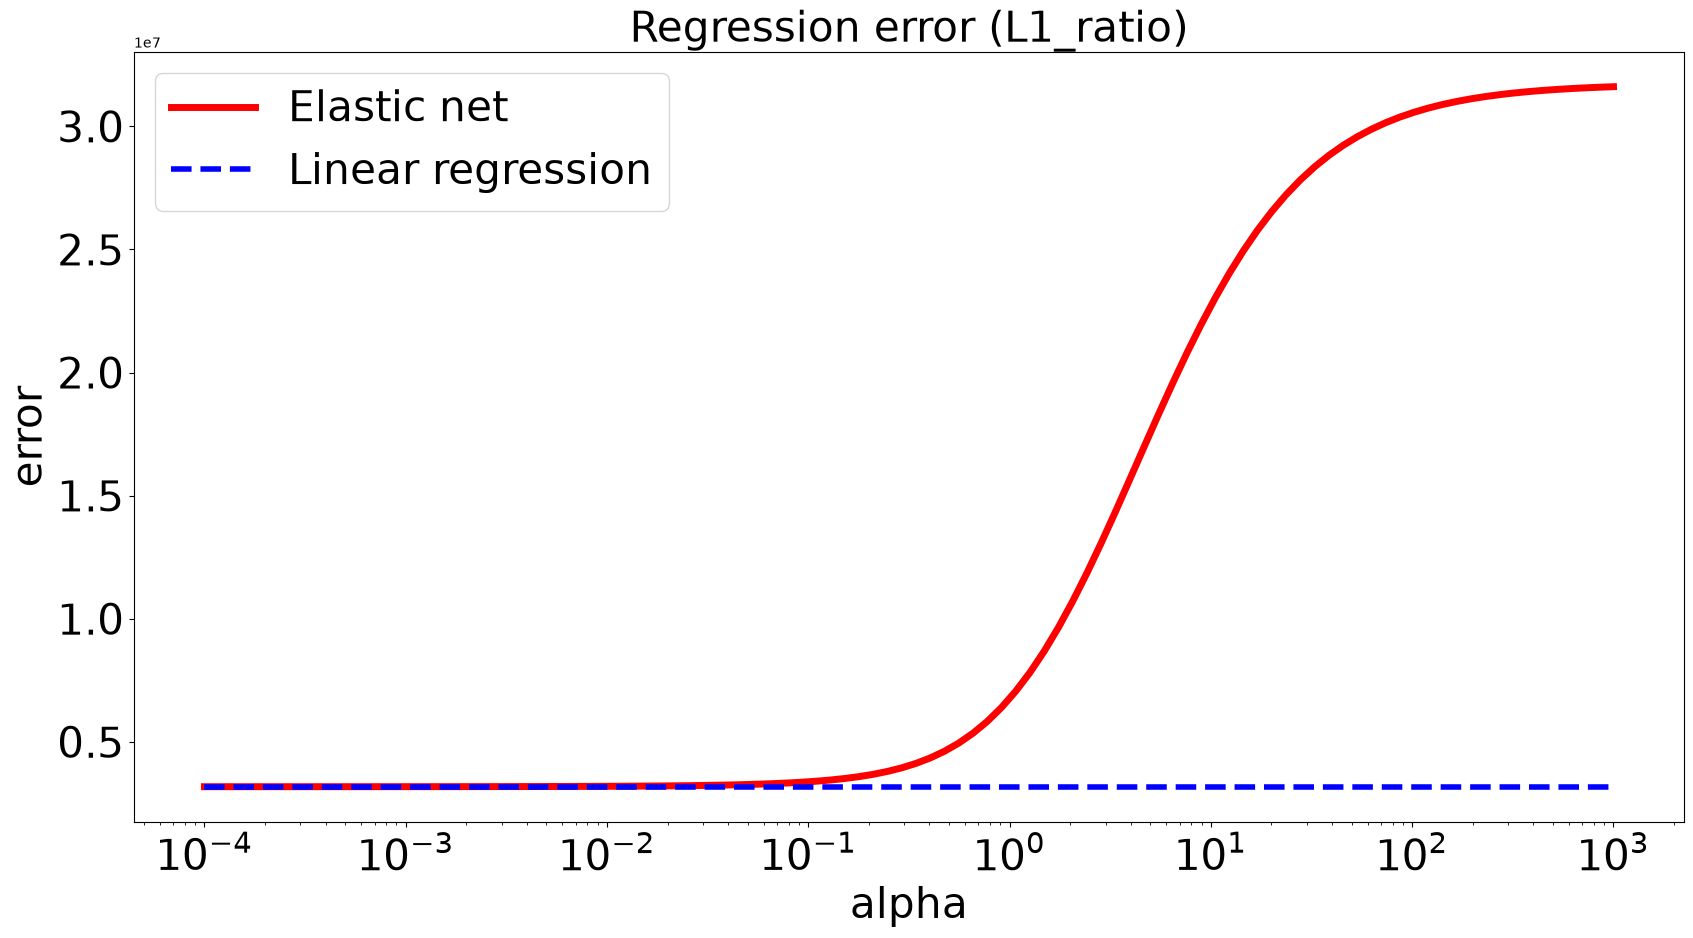

In [59]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()

### Modelos Polinómicos

In [60]:
# Hacemos solo de X_train para no pasarle info previa de test

from sklearn.preprocessing import PolynomialFeatures

poly_feats = PolynomialFeatures(degree = 2)
poly_feats.fit(X_train_scal) # De aquí sacas el criterio de escalado y demás sólo de train, y luego se lo aplicas también a test

X_train_poly = poly_feats.transform(X_train_scal)
X_test_poly = poly_feats.transform(X_test_scal) # Aplicamos el criterio a test

In [61]:
pol_reg = LinearRegression()
pol_reg.fit(X_train_poly, y_train)

preds_test_poly = pol_reg.predict(X_test_poly)

In [62]:
print("MAE:", mean_absolute_error(y_test, preds_test_poly))
print("MAPE:", mean_absolute_percentage_error(y_test, preds_test_poly))
print("MSE:", mean_squared_error(y_test, preds_test_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test, preds_test_poly)))
print("r2_score train", pol_reg.score(X_train_poly, y_train))
print("r2_score test",pol_reg.score(X_test_poly, y_test))

MAE: 526.1794444043732
MAPE: 0.04893877124817125
MSE: 412910.2285378996
RMSE: 642.5809120553611
r2_score train 0.986104518792419
r2_score test 0.9869181490609604


In [63]:
from sklearn.linear_model import Ridge

ridgePoly = Ridge(alpha = 0.001)
ridgePoly.fit(X_train_poly, y_train)

print("Train MSE sin regularización:", round(metrics.mean_squared_error(y_train, pol_reg.predict(X_train_poly)),2))
print("Test MSE sin regularización:", round(metrics.mean_squared_error(y_test, pol_reg.predict(X_test_poly)),2))

print("Train MSE con regularización:", round(metrics.mean_squared_error(y_train, ridgePoly.predict(X_train_poly)),2))
print("Test MSE con regularización:", round(metrics.mean_squared_error(y_test, ridgePoly.predict(X_test_poly)),2))

baseline_error_poly = metrics.mean_squared_error(y_test, preds_test_poly)

Train MSE sin regularización: 360396.67
Test MSE sin regularización: 412910.23
Train MSE con regularización: 360396.68
Test MSE con regularización: 412908.96


In [64]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

coef_ridge_poly = []
err_ridge_poly = []
baseline_poly = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_poly, y_train)
    
    coef_ridge_poly.append(ridge.coef_)
    
    y_pred = ridge.predict(X_test_poly)
    ridge_error = metrics.mean_squared_error(y_pred, y_test)
    
    err_ridge_poly.append(ridge_error)
    baseline_poly.append(baseline_error_poly)

In [65]:
min(err_ridge_poly)

412623.6576957221

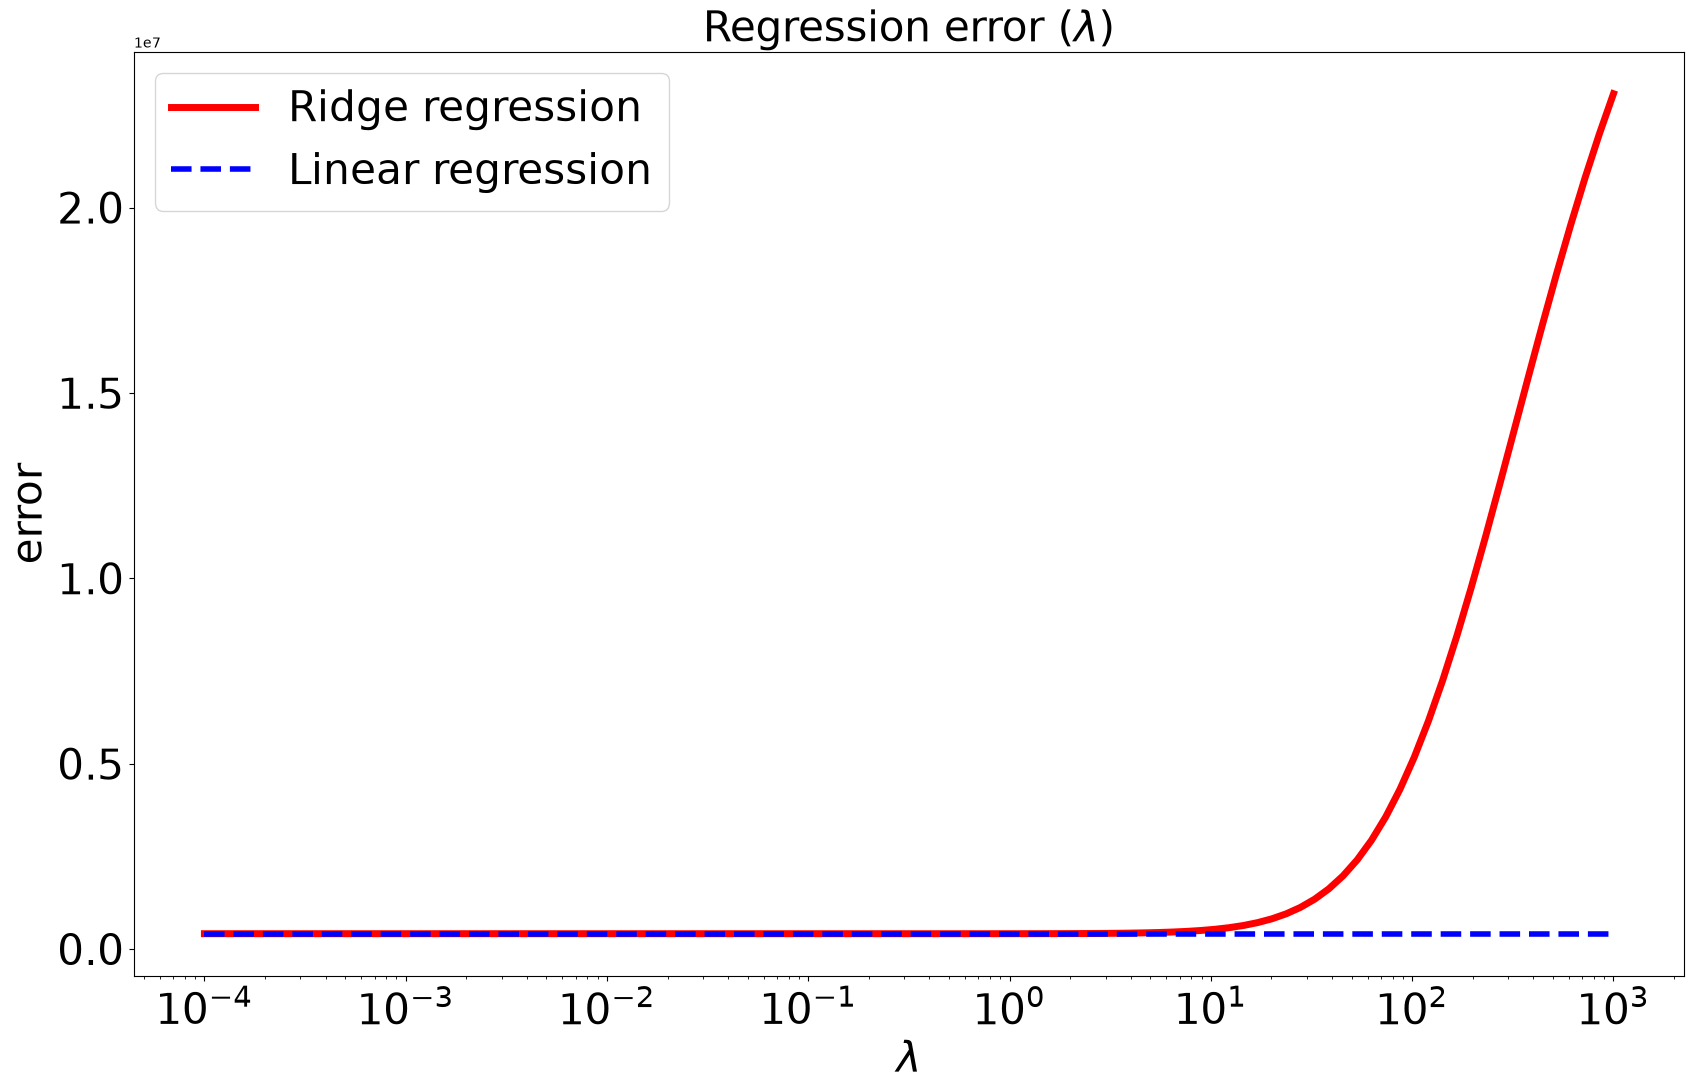

In [66]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge_poly, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline_poly, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [67]:
lasso_poly = linear_model.Lasso()

coef_lasso_poly = []
err_lasso_poly = []

for a in alphas:
    lasso_poly.set_params(alpha=a)
    lasso_poly.fit(X_train_poly, y_train)
    coef_lasso_poly.append(lasso_poly.coef_)
    y_pred = lasso_poly.predict(X_test_poly)
    lasso_error_poly = metrics.mean_squared_error(y_pred, y_test)    
    err_lasso_poly.append(lasso_error_poly)

In [68]:
indice_min_lasso = err_lasso_poly.index(min(err_lasso_poly))
alphas[indice_min_lasso]

np.float64(38.53528593710527)

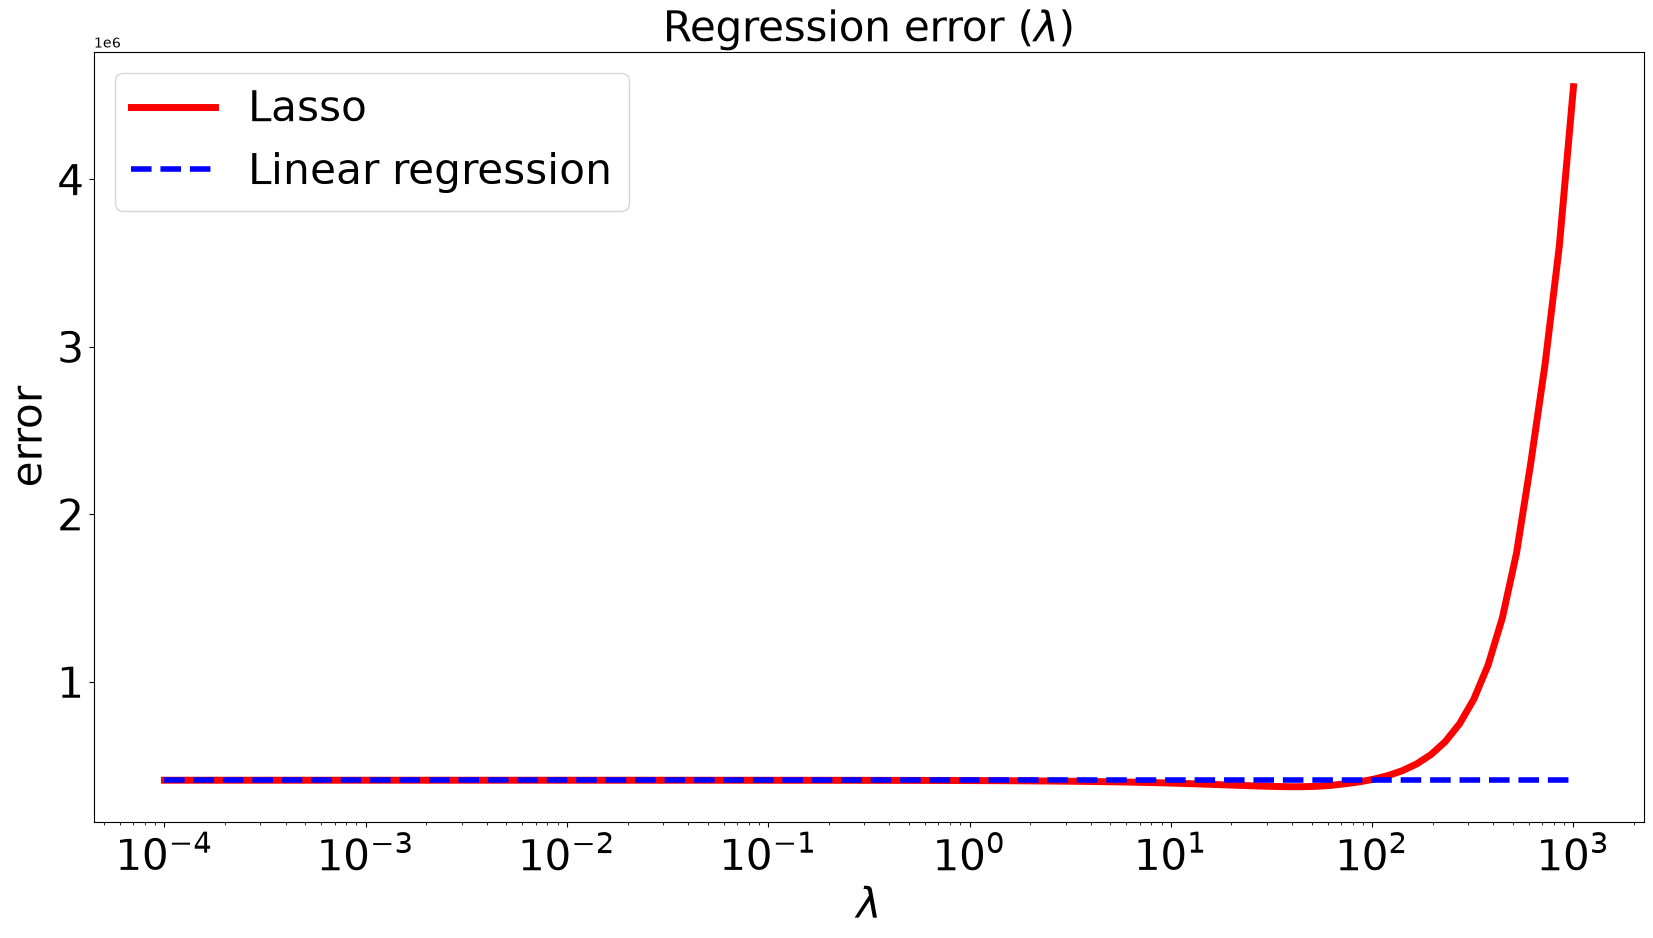

In [69]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_lasso_poly, linewidth=5, color='red', label="Lasso")
ax.plot(alphas, baseline_poly, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [70]:
coef_eln_poly = []
err_eln_poly = []
baseline_poly = []
for a in alphas:
    elastic_net = ElasticNet(alpha = a, l1_ratio=0.5)
    elastic_net.fit(X_train_poly, y_train)
    coef_eln_poly.append(elastic_net.coef_)
    y_pred = elastic_net.predict(X_test_poly)
    elasticnet_error = metrics.mean_squared_error(y_pred, y_test)
    err_eln_poly.append(elasticnet_error)
    baseline_poly.append(baseline_error_poly)
    

In [71]:
min(err_eln_poly)

412617.57498181047

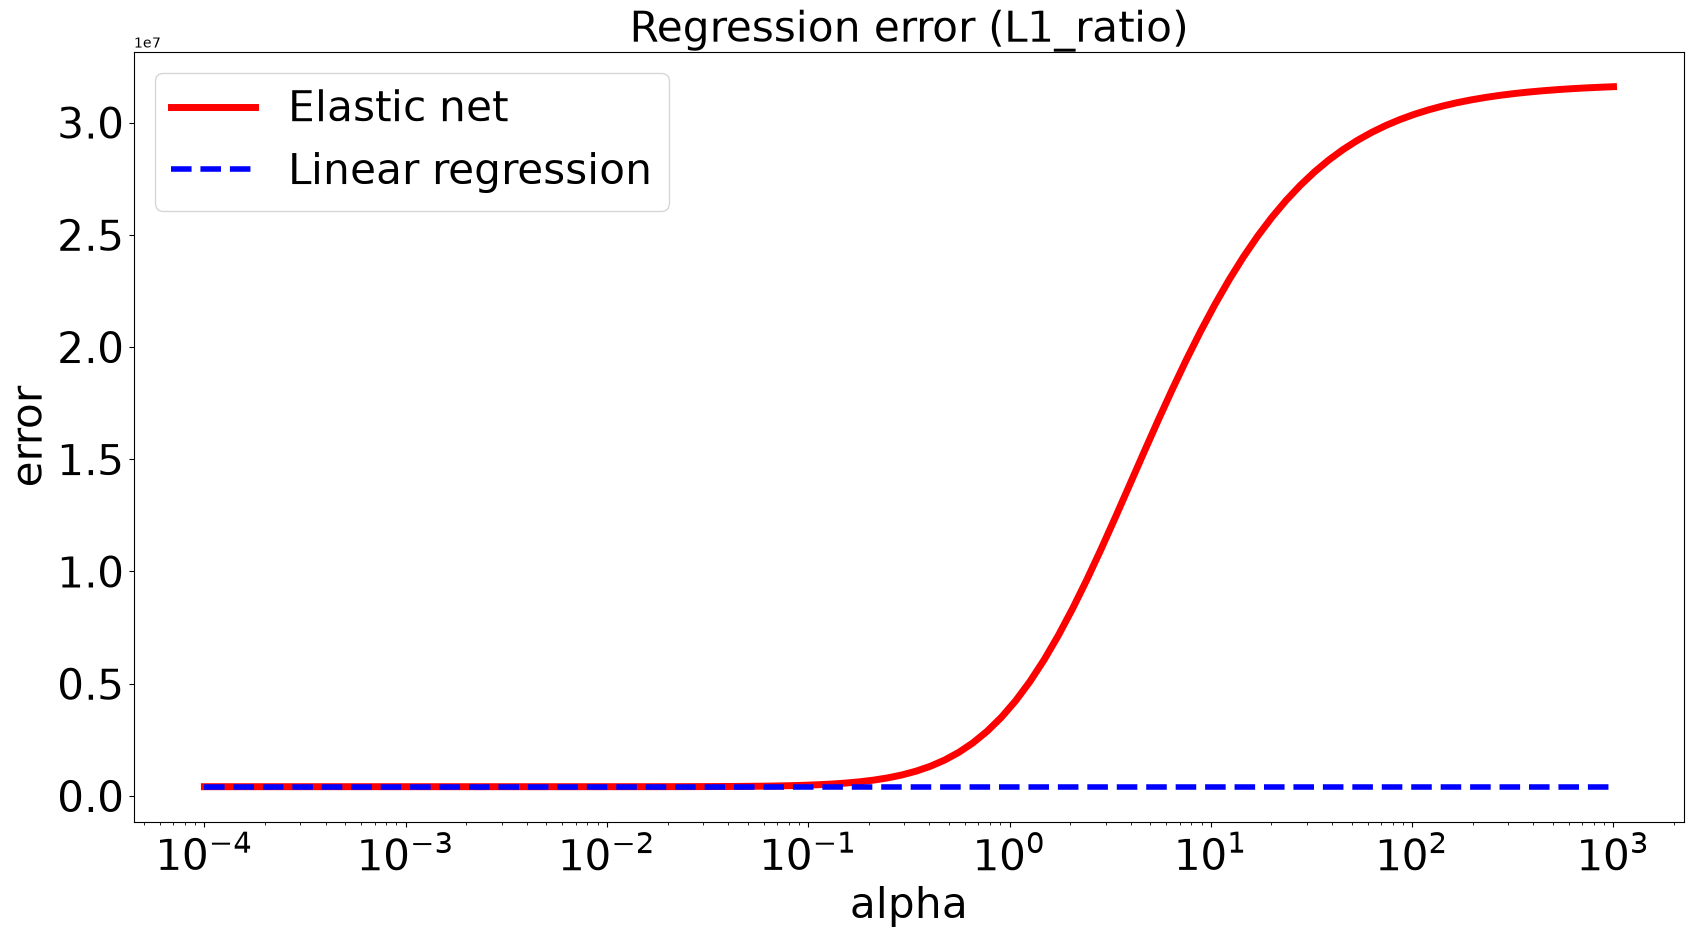

In [72]:
plt.figure(figsize=(20,10))
ax = plt.gca()
ax.plot(alphas, err_eln_poly, linewidth=5, color='red', label="Elastic net")
ax.plot(alphas, baseline_poly, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel('alpha', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error (L1_ratio)', fontsize=30)
plt.show()

## Resultados

In [73]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [74]:
# Lineales
print("Linear regression error:   %0.4f" % baseline_error)    
print("Minimun ridge error:       %0.4f" % min(err_ridge))
print("Minimum lasso error:       %0.4f" % min(err_lasso))
print("Minimum elastic net error: %0.4f" % min(err_eln))

print()

# Polis
print("Linear regression error - poli:   %0.4f" % baseline_error_poly)    
print("Minimun ridge error - poli:       %0.4f" % min(err_ridge_poly))
print("Minimum lasso error - poli:       %0.4f" % min(err_lasso_poly))
print("Minimum elastic net error - poli: %0.4f" % min(err_eln_poly))

Linear regression error:   3174097.3540
Minimun ridge error:       3174099.2809
Minimum lasso error:       3173904.8960
Minimum elastic net error: 3174251.5613

Linear regression error - poli:   412910.2285
Minimun ridge error - poli:       412623.6577
Minimum lasso error - poli:       374315.4184
Minimum elastic net error - poli: 412617.5750


In [75]:
# Vemos que el error mínimo lo encontramos con el modelo LASSO con las variables polinómicas (de grado 2).

In [76]:
lassoR = Lasso(alpha=38.53)
lassoR.fit(X_train_poly, y_train)

print("Train MSE - sin regularización:", round(metrics.mean_squared_error(y_train, pol_reg.predict(X_train_poly)),2))
print("Test MSE - sin regularización:", round(metrics.mean_squared_error(y_test, pol_reg.predict(X_test_poly)),2))

print("Train poli MSE - LASSO: %0.4f" % metrics.mean_squared_error(y_train, lassoR.predict(X_train_poly)))
print("Test poli MSE - LASSO: %0.4f" % metrics.mean_squared_error(y_test, lassoR.predict(X_test_poly)))

Train MSE - sin regularización: 360396.67
Test MSE - sin regularización: 412910.23
Train poli MSE - LASSO: 372668.3012
Test poli MSE - LASSO: 374316.1422


In [77]:
r2_test_lasso = lassoR.score(X_test_poly, y_test)
print(f"R2 en test: {r2_test_lasso}")

# R2 en los datos de entrenamiento (train) para comparar si hay overfitting
r2_train_lasso = lassoR.score(X_train_poly, y_train)
print(f"R2 en train: {r2_train_lasso}")

R2 en test: 0.9881408896213741
R2 en train: 0.9856313730334849
